# PaScaL_TCS Fig 9 — NOB RBC glycerol
**Ra=10⁶, Pr=2547, Γ=6, 128³**  
Θ_c = ⟨θ⟩_{x,y,t} at z=H/2 (center plane mean temperature)  
OB → Θ_c = 0,  NOB → Θ_c > 0 증가

In [1]:
import re, os
import numpy as np
import matplotlib.pyplot as plt

HERE = os.path.dirname(os.path.abspath('fig9.ipynb'))
LOG  = os.path.normpath(os.path.join(HERE, '../../../log'))

# ── CSV: 논문 원본 데이터 (x=dT [K], y=(T_c - T_m) [K]) ──────────────────
def load_csv(name):
    path = os.path.join(HERE, name)
    data = np.loadtxt(path, delimiter=',')
    return data[:, 0], data[:, 1]   # x, y

dT_pascal, Tc_pascal = load_csv('PaScaL_TCS.csv')
dT_horn,   Tc_horn   = load_csv('Horm_et_al.csv')

# ── 시뮬레이션 로그 파싱 ──────────────────────────────────────────────────
def parse_log(path):
    steps, ts, tcs = [], [], []
    pat = re.compile(r'step=(\d+)\s+t=([\d.e+-]+).*?Theta_c=([\d.e+-]+)')
    try:
        with open(path) as f:
            for line in f:
                m = pat.search(line)
                if m:
                    steps.append(int(m.group(1)))
                    ts.append(float(m.group(2)))
                    tcs.append(float(m.group(3)))
    except FileNotFoundError:
        pass
    return np.array(steps), np.array(ts), np.array(tcs)

logs128 = {
    20: os.path.join(LOG, 'fig9_128_20_29278.out'),
    40: os.path.join(LOG, 'fig9_128_40_29279.out'),
    60: os.path.join(LOG, 'fig9_128_60_29280.out'),
}
DTs = [20, 40, 60]
data128 = {dt: parse_log(p) for dt, p in logs128.items()}

# ── 평균 계산: 무차원 -> 차원 (K) 변환  ──────────────────────────────────
# center_temp() 반환값 theta_c in [-0.5, +0.5]; 차원값 = theta_c * dT
NSTAT = 20000
def mean128_K(dt):
    if dt not in data128: return float('nan')
    steps, ts, tcs = data128[dt]
    if len(tcs) == 0: return float('nan')
    mask = steps >= NSTAT
    theta_mean = float(tcs[mask].mean()) if mask.any() else float(tcs[-max(1,len(tcs)//4):].mean())
    return theta_mean * dt   # 무차원 -> K

print('데이터 로드 완료')
print(f'  PaScaL_TCS: {len(dT_pascal)} points,  dT=[{dT_pascal[0]:.1f}, {dT_pascal[-1]:.1f}] K')
print(f'  Horn et al: {len(dT_horn)} points,  dT=[{dT_horn[0]:.1f}, {dT_horn[-1]:.1f}] K')
for dt in DTs:
    steps, ts, tcs = data128[dt]
    val_K = mean128_K(dt)
    print(f'  128^3 dT={dt:2d}K: {len(steps):4d} steps, Theta_c(dim)={val_K:.3f} K  '
          f'(paper={dT_pascal[np.argmin(np.abs(dT_pascal-dt))]:.1f}K -> {Tc_pascal[np.argmin(np.abs(dT_pascal-dt))]:.3f} K)')


데이터 로드 완료
  PaScaL_TCS: 3 points,  dT=[20.0, 59.6] K
  Horn et al: 32 points,  dT=[8.2, 68.9] K
  128^3 dT=20K:   70 steps, Theta_c(dim)=0.318 K  (paper=20.0K -> 1.486 K)
  128^3 dT=40K:   70 steps, Theta_c(dim)=1.170 K  (paper=39.9K -> 5.400 K)
  128^3 dT=60K:   68 steps, Theta_c(dim)=6.328 K  (paper=59.6K -> 11.400 K)


## Fig 9 — Θ_c vs ΔT
논문 원래 형식: 점+선 그래프

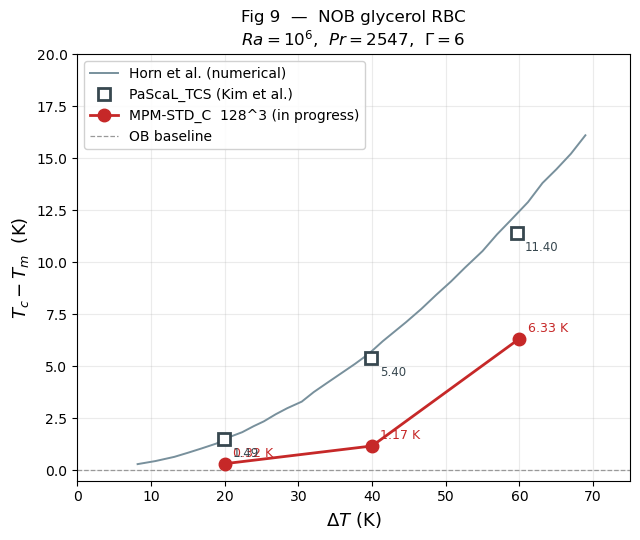

saved fig9_main.png


In [2]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# Horn et al. 곡선
ax.plot(dT_horn, Tc_horn, '-', color='#78909C', lw=1.4,
        label='Horn et al. (numerical)', zorder=2)

# PaScaL_TCS 심볼
ax.plot(dT_pascal, Tc_pascal, 's', color='#37474F', ms=9, mfc='white', mew=2.0,
        label='PaScaL_TCS (Kim et al.)', zorder=4)

# 우리 결과 (128^3)
sim_dT  = np.array(DTs, dtype=float)
sim_Tc  = np.array([mean128_K(d) for d in DTs])
mask = ~np.isnan(sim_Tc)
if mask.any():
    ax.plot(sim_dT[mask], sim_Tc[mask], 'o-', color='#C62828', lw=2.0, ms=9,
            label='MPM-STD_C  128^3 (in progress)', zorder=5)
    for d, v in zip(sim_dT[mask], sim_Tc[mask]):
        ax.annotate(f'{v:.2f} K', (d, v), textcoords='offset points',
                    xytext=(6, 5), fontsize=9, color='#C62828')

# PaScaL_TCS 수치 표기
for d, v in zip(dT_pascal, Tc_pascal):
    ax.annotate(f'{v:.2f}', (d, v), textcoords='offset points',
                xytext=(6, -13), fontsize=8.5, color='#37474F')

ax.axhline(0, color='0.6', lw=0.9, ls='--', label='OB baseline')
ax.set_xlabel(r'$\Delta T$ (K)', fontsize=13)
ax.set_ylabel(r'$T_c - T_m$  (K)', fontsize=13)
ax.set_title('Fig 9  —  NOB glycerol RBC\n'
             r'$Ra=10^6$,  $Pr=2547$,  $\Gamma=6$', fontsize=12)
ax.set_xlim(0, 75)
ax.set_ylim(-0.5, 20)
ax.legend(fontsize=10, framealpha=0.9)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig('fig9_main.png', dpi=180, bbox_inches='tight')
plt.show()
print('saved fig9_main.png')


## Θ_c 시계열 — 수렴 확인

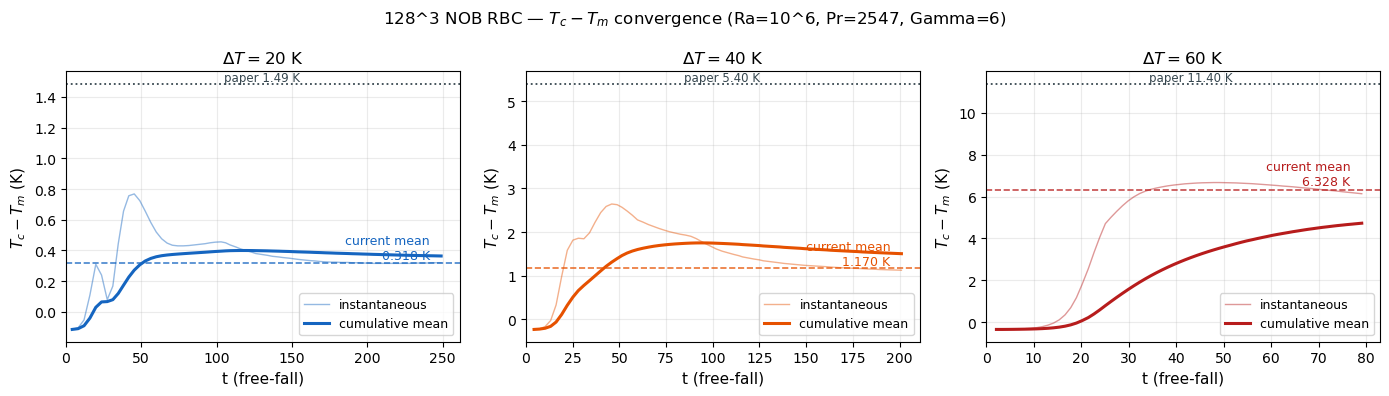

saved fig9_timeseries.png


In [3]:
clr = {20: '#1565C0', 40: '#E65100', 60: '#B71C1C'}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=False)

for ax, dt in zip(axes, DTs):
    steps, ts, tcs = data128[dt]
    if len(tcs) == 0:
        ax.text(0.5, 0.5, 'no data', ha='center', va='center', transform=ax.transAxes)
        continue
    c = clr[dt]
    tcs_K = tcs * dt   # K 단위로 변환

    ax.plot(ts, tcs_K, color=c, lw=1.0, alpha=0.45, label='instantaneous')

    cumean = np.cumsum(tcs_K) / np.arange(1, len(tcs_K)+1)
    ax.plot(ts, cumean, color=c, lw=2.2, label='cumulative mean')

    mu_K = mean128_K(dt)
    ax.axhline(mu_K, color=c, ls='--', lw=1.2, alpha=0.8)
    ax.text(ts[-1]*0.97, mu_K+0.03*ax.get_ylim()[1] if len(ts)>0 else 0,
            f'current mean\n{mu_K:.3f} K', ha='right', fontsize=9, color=c)

    # 논문 참조값
    idx = np.argmin(np.abs(dT_pascal - dt))
    ref_K = Tc_pascal[idx]
    ax.axhline(ref_K, color='#37474F', ls=':', lw=1.3)
    ax.text(ts[len(ts)//2] if len(ts)>0 else 1, ref_K,
            f'paper {ref_K:.2f} K', ha='center', va='bottom', fontsize=8.5, color='#37474F')

    ax.set_xlabel('t (free-fall)', fontsize=11)
    ax.set_ylabel(r'$T_c - T_m$ (K)', fontsize=11)
    ax.set_title(f'$\\Delta T = {dt}$ K', fontsize=12)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.25)
    ax.set_xlim(left=0)

fig.suptitle(r'128^3 NOB RBC — $T_c - T_m$ convergence (Ra=10^6, Pr=2547, Gamma=6)', fontsize=12)
plt.tight_layout()
plt.savefig('fig9_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved fig9_timeseries.png')


## 수치 요약

In [4]:
print('{:>5}  {:>10}  {:>10}  {:>10}  {:>8}'.format(
    'dT(K)', 'Paper(K)', '128^3(K)', 'ratio', 'status'))
print('-'*55)
for dt in DTs:
    idx = np.argmin(np.abs(dT_pascal - dt))
    p   = Tc_pascal[idx]
    s   = mean128_K(dt)
    r   = s/p if not np.isnan(s) and p > 0 else float('nan')
    steps, ts, tcs = data128[dt]
    stat = 'done' if (steps >= NSTAT).any() else 'running (step {})'.format(steps[-1] if len(steps) else 0)
    print('{:>4}K  {:>10.3f}  {:>10.3f}  {:>10.3f}  {}'.format(dt, p, s, r, stat))
print()
print('* paper values: nearest dT point from PaScaL_TCS.csv')
print('* 128^3: multiplied by dT to convert dimensionless -> K')


dT(K)    Paper(K)    128^3(K)       ratio    status
-------------------------------------------------------
  20K       1.486       0.318       0.214  running (step 17500)
  40K       5.400       1.170       0.217  running (step 17500)
  60K      11.400       6.328       0.555  running (step 17000)

* paper values: nearest dT point from PaScaL_TCS.csv
* 128^3: multiplied by dT to convert dimensionless -> K


## 수렴 진단

In [5]:
# ── 수렴 진단 ─────────────────────────────────────────────────────────────
# 기준 1: 누적 평균의 후반 기울기 (slope of last 25%)
# 기준 2: 후반 4블록 평균의 상대 표준편차 (CV)
# 기준 3: 현재 통계 단계 (step >= NSTAT 도달 여부)

def convergence_diag(dt, n_blocks=4):
    steps, ts, tcs = data128[dt]
    if len(tcs) < 20:
        return {'status': 'no data'}

    tcs_K = tcs * dt

    # 기준 1: 누적 평균 후반 25% 기울기
    cumean = np.cumsum(tcs_K) / np.arange(1, len(tcs_K)+1)
    n = len(cumean)
    tail = cumean[3*n//4:]
    t_tail = ts[3*n//4:]
    slope = np.polyfit(t_tail, tail, 1)[0]          # K / free-fall time
    slope_rel = abs(slope) / (cumean[-1]+1e-12)      # 상대 기울기

    # 기준 2: 후반 절반을 n_blocks개 블록으로 나눠 CV 계산
    half = tcs_K[n//2:]
    block_size = len(half) // n_blocks
    if block_size < 2:
        cv = float('nan')
    else:
        block_means = [half[i*block_size:(i+1)*block_size].mean()
                       for i in range(n_blocks)]
        cv = np.std(block_means) / (np.mean(block_means)+1e-12)

    # 기준 3: 통계 창 도달 여부
    in_stat = bool((steps >= NSTAT).any())
    cur_step = int(steps[-1])

    return {
        'current_mean_K': float(cumean[-1]),
        'slope_K_per_tf': float(slope),
        'slope_rel_%':    float(slope_rel*100),
        'block_CV_%':     float(cv*100),
        'in_stat_window': in_stat,
        'current_step':   cur_step,
    }

print(f"{'dT':>5}  {'mean(K)':>8}  {'slope(%/tf)':>12}  {'block_CV%':>10}  {'stat_win':>8}  {'step':>7}  판정")
print('-'*75)
for dt in DTs:
    d = convergence_diag(dt)
    if 'status' in d:
        print(f'{dt:>4}K  -- no data --')
        continue
    # 수렴 판정: 기울기 < 0.5%/tf AND CV < 5%
    ok_slope = d['slope_rel_%'] < 0.5
    ok_cv    = d['block_CV_%']  < 5.0
    ok_stat  = d['in_stat_window']
    verdict = 'CONVERGED' if (ok_slope and ok_cv and ok_stat) else 'not yet'
    print(f"{dt:>4}K  {d['current_mean_K']:>8.3f}  "
          f"{d['slope_rel_%']:>12.3f}  {d['block_CV_%']:>10.1f}  "
          f"{'YES' if ok_stat else 'NO':>8}  {d['current_step']:>7}  {verdict}")

print()
print('수렴 기준: 기울기 < 0.5%/free-fall, 블록 CV < 5%, step >= NSTAT')


   dT   mean(K)   slope(%/tf)   block_CV%  stat_win     step  판정
---------------------------------------------------------------------------
  20K     0.364         0.069         4.9        NO    17500  not yet
  40K     1.506         0.147         8.7        NO    17500  not yet
  60K     4.729         0.618         2.3        NO    17000  not yet

수렴 기준: 기울기 < 0.5%/free-fall, 블록 CV < 5%, step >= NSTAT
